In [10]:
import numpy as np
import matplotlib.pyplot as plt

def DFT(x_n, N):

    # Definição da matriz W_n
    W_n = np.zeros((N,N), dtype=complex)

    for k in range (0, N, 1):
        for n in range (0, N, 1):
            W_n[k][n] = W_kn_N(k,n,N)

    # Cálculo da DFT
    X_k = np.zeros(N, dtype=complex)
    for k in range(N):
        X_k[k] = np.sum(W_n[k] * x_n )

    return X_k

def W_kn_N (k,n,N):
    return np.exp(-2j * np.pi * k * n / N)


In [11]:
def FFT (x_n):

    X = np.array(x_n, dtype=complex)
    N = len(X)

    # Validação: N deve ser potência de 2
    if (N <= 0) or (N & (N - 1) != 0):
        raise ValueError("O tamanho do sinal N precisa ser uma potência de 2.")

    num_estagios = int(np.log2(N))

    for estagio in range(num_estagios):

        N_atual = N // (2 ** estagio)
        N_2 = N_atual // 2

        for inicio in range(0, N, N_atual):
            for k in range(N_2):
                W_nN = W_kn_N(1, k, N_atual)

                idx1 = inicio + k
                idx2 = inicio + k + N_2

                u = X[idx1]
                v = X[idx2]

                X[idx1] = u + v
                X[idx2] = (u - v) * W_nN

    X_k = np.zeros(N, dtype=complex)
    for k in range(N):
        idx_invertido = int(f"{k:0{num_estagios}b}"[::-1], 2)
        X_k[idx_invertido] = X[k]

    return X_k

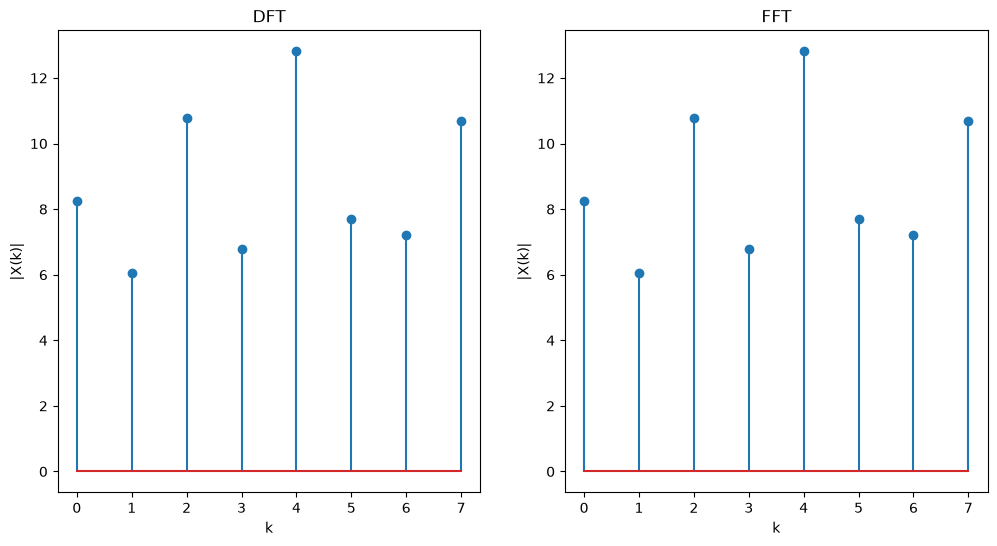

Os resultados são iguais? True


In [12]:
# Sinal x(n) complexo de teste:
x_n = np.array([1 + 2j, 3 - 1j, 0 + 4j, 2 + 2j, -1 + 0j, 5 - 3j, 0 + 0j, -2 - 2j], dtype=complex)

# Cálculo da DFT
X_k_dft = DFT(x_n, len(x_n))

# Cálculo da FFT
X_k_fft = FFT(x_n)

# Gráficos para visualizar os resultados e comparação
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.stem(range(len(x_n)), np.abs(X_k_dft))
plt.xlabel('k')
plt.ylabel('|X(k)|')
plt.title('DFT')

plt.subplot(1, 2, 2)
plt.stem(range(len(x_n)), np.abs(X_k_fft))
plt.xlabel('k')
plt.ylabel('|X(k)|')
plt.title('FFT')
plt.show()

# Compara a resposta completa (real + imaginário) da sua DFT com a FFT
print("Os resultados são iguais?", np.allclose(X_k_dft,X_k_fft))